# Analyse d'image

### Importation des modules

In [2]:
import pandas as pnd
import numpy as np
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split
import tensorflow as tf
import keras

tf.config.set_visible_devices([], 'GPU')

LONGUEUR_IMAGE = 28
LARGEUR_IMAGE = 28

observations_entrainement = pnd.read_csv('datas/fashion-mnist_train.csv')

I0000 00:00:1793927239.906253    3226 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793927239.942348    3226 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793927243.503614    3226 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793927253.207099    3226 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

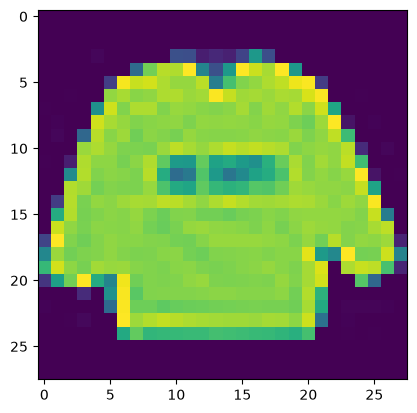

In [3]:
X = np.array(observations_entrainement.iloc[:, 1:])

premiereImage = X[0]
premiereImage = premiereImage.reshape([LONGUEUR_IMAGE,LARGEUR_IMAGE])
plt.imshow(premiereImage)
plt.show()

### Préparation des données d'apprentissage

In [4]:
y = keras.utils.to_categorical(np.array(observations_entrainement.iloc[:, 0]))

X_apprentissage, X_validation, y_apprentissage, y_validation = train_test_split(X, y, test_size=0.2, random_state=13)

In [5]:
X_apprentissage = X_apprentissage.reshape(X_apprentissage.shape[0], LARGEUR_IMAGE, LONGUEUR_IMAGE, 1)

X_apprentissage = X_apprentissage.astype('float32')
X_apprentissage /= 255

X_validation = X_validation.reshape(X_validation.shape[0], LARGEUR_IMAGE, LONGUEUR_IMAGE, 1)

X_validation = X_validation.astype('float32')
X_validation /= 255

### Préparation des données de tests

In [6]:
observations_test = pnd.read_csv('datas/fashion-mnist_test.csv')
X_test = np.array(observations_test.iloc[:, 1:])
y_test = tf.keras.utils.to_categorical(np.array(observations_test.iloc[:, 0]))
X_test = X_test.reshape(X_test.shape[0], LARGEUR_IMAGE, LONGUEUR_IMAGE, 1)

X_test = X_test.astype('float32')
X_test /= 255

### Configuration

In [7]:
from keras.models import Sequential
from keras.layers import Dense, Dropout, Flatten, Input
from keras.layers import Conv2D, MaxPooling2D

dimentionImage = (LARGEUR_IMAGE, LONGUEUR_IMAGE, 1)

reseauNeurone1Convolution = Sequential()

reseauNeurone1Convolution.add(Input(shape=dimentionImage))

reseauNeurone1Convolution.add(Conv2D(32, kernel_size=(3, 3), activation='relu'))

reseauNeurone1Convolution.add(MaxPooling2D(pool_size=(2, 2)))

reseauNeurone1Convolution.add(Dropout(0.2))

reseauNeurone1Convolution.add(Flatten())

reseauNeurone1Convolution.add(Dense(128, activation='relu'))

reseauNeurone1Convolution.add(Dense(10, activation='softmax'))

### Compilation, apprentissage et test

In [8]:
reseauNeurone1Convolution.compile(loss=keras.losses.categorical_crossentropy, optimizer=tf.keras.optimizers.Adam(), metrics=['accuracy'])

In [9]:
historique_apprentissage = reseauNeurone1Convolution.fit(X_apprentissage, y_apprentissage, batch_size=256, epochs=10, verbose=1, validation_data=(X_validation, y_validation))

Epoch 1/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 61s 288ms/step - accuracy: 0.8060 - loss: 0.5532 - val_accuracy: 0.8618 - val_loss: 0.3954
Epoch 2/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 48s 255ms/step - accuracy: 0.8687 - loss: 0.3709 - val_accuracy: 0.8821 - val_loss: 0.3438
Epoch 3/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 51s 272ms/step - accuracy: 0.8849 - loss: 0.3263 - val_accuracy: 0.8800 - val_loss: 0.3327
Epoch 4/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 46s 243ms/step - accuracy: 0.8927 - loss: 0.3007 - val_accuracy: 0.8937 - val_loss: 0.2998
Epoch 5/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 46s 246ms/step - accuracy: 0.9018 - loss: 0.2760 - val_accuracy: 0.8992 - val_loss: 0.2852
Epoch 6/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 78s 227ms/step - accuracy: 0.9079 - loss: 0.2590 - val_accuracy: 0.8997 - val_loss: 0.2802
Epoch 7/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 44s 231ms/step - accuracy: 0.9120 - loss: 0.2455 - val_accuracy: 0.9057 - val_loss: 0.2660
Epoch 8/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 84s 244ms/step - accuracy: 0.9161 - loss: 0

In [10]:
evaluation = reseauNeurone1Convolution.evaluate(X_test, y_test, verbose=0)
print('Erreur : ', evaluation[0])
print('Précision : ', evaluation[1])

Erreur :  0.2404550313949585
Précision :  0.9147999882698059


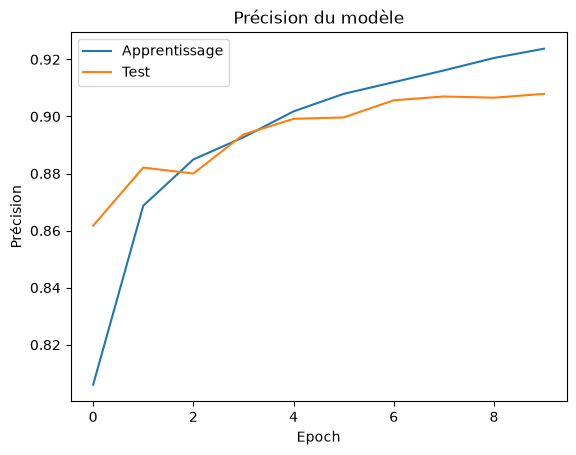

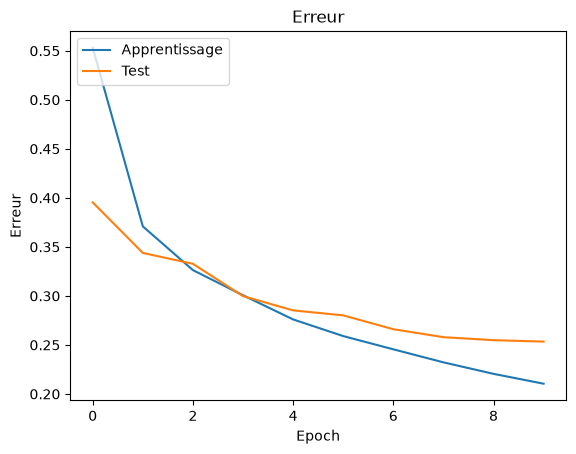

In [11]:
plt.plot(historique_apprentissage.history['accuracy'])
plt.plot(historique_apprentissage.history['val_accuracy'])
plt.title('Précision du modèle')
plt.ylabel('Précision')
plt.xlabel('Epoch')
plt.legend(['Apprentissage', 'Test'], loc='upper left')
plt.show()
### Plot training & validation loss values
plt.plot(historique_apprentissage.history['loss'])
plt.plot(historique_apprentissage.history['val_loss'])
plt.title('Erreur')
plt.ylabel('Erreur')
plt.xlabel('Epoch')
plt.legend(['Apprentissage', 'Test'], loc='upper left')
plt.show()

### Augmentation du nombre de données

In [15]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

generateur_images = tf.keras.preprocessing.image.ImageDataGenerator(rotation_range=8, width_shift_range=0.08, shear_range=0.3, height_shift_range=0.08, zoom_range=0.08)

In [19]:
nouvelles_images_apprentissage = generateur_images.flow(X_apprentissage, y_apprentissage, batch_size=256)

nouvelles_images_validation = generateur_images.flow(X_validation, y_validation, batch_size=256)

historique_apprentissage = reseauNeurone1Convolution.fit(nouvelles_images_apprentissage, steps_per_epoch=48000//256, epochs=50, validation_data=nouvelles_images_validation, validation_steps=12000//256,verbose=1)

evaluation = reseauNeurone1Convolution.evaluate(X_test, y_test, verbose=0)

print('Erreur :', evaluation[0])
print('Précision :', evaluation[1])

Epoch 1/50


I0000 00:00:1793928514.199545    3226 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.


187/187 ━━━━━━━━━━━━━━━━━━━━ 101s 531ms/step - accuracy: 0.8244 - loss: 0.4686 - val_accuracy: 0.8459 - val_loss: 0.4247
Epoch 2/50
  1/187 ━━━━━━━━━━━━━━━━━━━━ 1:04 348ms/step - accuracy: 0.8633 - loss: 0.3891

/home/thien/Documents/5G4/420-5G4-ML/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


187/187 ━━━━━━━━━━━━━━━━━━━━ 10s 53ms/step - accuracy: 0.8633 - loss: 0.3891 - val_accuracy: 0.8419 - val_loss: 0.4257
Epoch 3/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 143s 594ms/step - accuracy: 0.8462 - loss: 0.4116 - val_accuracy: 0.8445 - val_loss: 0.4134
Epoch 4/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 22s 115ms/step - accuracy: 0.8125 - loss: 0.4208 - val_accuracy: 0.8501 - val_loss: 0.4074
Epoch 5/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 116s 618ms/step - accuracy: 0.8528 - loss: 0.3973 - val_accuracy: 0.8568 - val_loss: 0.3822
Epoch 6/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 20s 105ms/step - accuracy: 0.8438 - loss: 0.4159 - val_accuracy: 0.8530 - val_loss: 0.3850
Epoch 7/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 97s 514ms/step - accuracy: 0.8591 - loss: 0.3801 - val_accuracy: 0.8618 - val_loss: 0.3752
Epoch 8/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 21s 112ms/step - accuracy: 0.8789 - loss: 0.3412 - val_accuracy: 0.8590 - val_loss: 0.3774
Epoch 9/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 203s 1s/step - accuracy: 0.8617 - loss: 0.3718 - val_

### Sauvegarde du modèle

In [ ]:
model_json = reseauNeurone1Convolution.to_json()
with open("modele/modele.json", "w") as json_file: json_file.write(model_json)

reseauNeurone1Convolution.save_weights("modele/modele.weights.h5")
print("Modèle sauvegardé !")

In [ ]:
from keras.layers import BatchNormalization

reseauNeurones4Convolution = Sequential()

reseauNeurones4Convolution.add(Conv2D(32, kernel_size(3, 3), activation='relu', input_shape=dimentionImage))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(Conv2D(32, kernel_size(3, 3), activation='relu'))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(MaxPooling2D(pool_size=(2, 2)))
reseauNeurones4Convolution.add(Dropout(0.25))

reseauNeurones4Convolution.add(Conv2D(64, kernel_size(3, 3), activation='relu'))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(Dropout(0.25))

reseauNeurones4Convolution.add(Conv2D(128, kernel_size(3, 3), activation='relu'))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(MaxPooling2D(pool_size=(2, 2)))
reseauNeurones4Convolution.add(Dropout(0.25))

reseauNeurones4Convolution.add(Flatten())
reseauNeurones4Convolution.add(Dense(512, activation='relu'))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(Dropout(0.5))

reseauNeurones4Convolution.add(Dense(128, activation='relu'))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(Dropout(0.5))

reseauNeurones4Convolution.add(Dense(10, activation='softmax'))

In [ ]:
reseauNeurones4Convolution.compile(loss=keras.losses.categorical_crossentropy, optimizer=tf.keras.optimizers.Adam(), metrics=['accuracy'])

historique_apprentissage = reseauNeurones4COnvolution.fit(X_apprentissage, y_apprentissage, batch_size=256,epochs=10, verbose=1, validation_data=(X_validation, y_validation))

In [ ]:
evaluation = reseauNeurones4Convolution.evaluate(X_test, y_test, verbose=0)
print('Erreur :', evaluation[0])
print('Précision :', evaluation[1])

In [ ]:
historique_apprentissage = reseauNeurones4Convolution.fit(nouvelles_images_apprentissage, steps_per_epoch=48000//256, epochs=50, validation_data=nouvelles_images_validation, validation_steps=12000//256, verbose=1)

evaluation = reseauNeurones4Convolution.evaluate(X_test, y_test, verbose=0)

print('Erreur :', evaluation[0])
print('Précision :', evaluation[1])